# FGSM vs. PGD

FGSM takes one step of size epsilon. PGD (Projected Gradient Descent, Madry et al., 2018) takes many small steps and projects back into the epsilon-ball after each one. PGD is the standard strong attack, so it shows whether the models are really robust or only robust to FGSM.

This notebook does not retrain anything. It loads the models saved by the two main notebooks from `saved_models/`, so run those first.

Two things to check:
- **Logistic regression (sanity check):** for a binary linear model, FGSM already finds the worst-case perturbation, so PGD should give the same accuracy.
- **CNNs and ResNets:** PGD should be stronger than FGSM, especially for the adversarially trained models.

In [1]:
import json

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset

from advrobust.utils import SEED, device, set_seed
from advrobust.data import test_loader_bin, test_loader_bin_img, test_loader, load_stl10
from advrobust.models import (
    BinaryLogReg,
    BinaryCNNMNIST,
    MulticlassCNNMNIST,
    MulticlassCNNSTL10,
    BinaryResNetSTL10,
    MulticlassResNetSTL10,
)
from advrobust.evaluate import evaluate_clean, evaluate_fgsm, evaluate_pgd

print("Using device:", device)

Using device: mps


In [2]:
stl = load_stl10()
stl_test_loader_bin_img = stl["stl_test_loader_bin_img"]

# PGD is 10x slower than FGSM, so for STL-10 multiclass (8000 test images)
# we use a random subset of 2000 test images
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(stl["stl_test"]), generator=g)[:2000]
stl_test_loader_sub = DataLoader(Subset(stl["stl_test"], idx.tolist()), batch_size=128, shuffle=False)

In [3]:
def load_model(model, name):
    state = torch.load("saved_models/" + name + ".pt", map_location=device)
    model.load_state_dict(state)
    return model.to(device).eval()

EPSILONS_MNIST = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25]
EPSILONS_STL = [0.0, 0.005, 0.01, 0.015, 0.02, 0.025]

# (title, standard model, adversarially trained model, test loader, binary, epsilons)
settings = [
    ("MNIST binary, logistic regression",
     load_model(BinaryLogReg(), "model_none"), load_model(BinaryLogReg(), "model_adv"),
     test_loader_bin, True, EPSILONS_MNIST),
    ("MNIST binary, CNN",
     load_model(BinaryCNNMNIST(), "cnn_bin_MNIST"), load_model(BinaryCNNMNIST(), "cnn_bin_MNIST_adv"),
     test_loader_bin_img, True, EPSILONS_MNIST),
    ("MNIST multiclass, CNN",
     load_model(MulticlassCNNMNIST(), "cnn_mc_MNIST"), load_model(MulticlassCNNMNIST(), "cnn_mc_adv"),
     test_loader, False, EPSILONS_MNIST),
    ("STL-10 multiclass, CNN",
     load_model(MulticlassCNNSTL10(), "stl_cnn_mc"), load_model(MulticlassCNNSTL10(), "stl_cnn_mc_adv"),
     stl_test_loader_sub, False, EPSILONS_STL),
    ("STL-10 binary, ResNet-18",
     load_model(BinaryResNetSTL10(), "stl_resnet_bin"), load_model(BinaryResNetSTL10(), "stl_resnet_bin_adv"),
     stl_test_loader_bin_img, True, EPSILONS_STL),
    ("STL-10 multiclass, ResNet-18",
     load_model(MulticlassResNetSTL10(), "stl_resnet_mc"), load_model(MulticlassResNetSTL10(), "stl_resnet_mc_adv"),
     stl_test_loader_sub, False, EPSILONS_STL),
]

## Run both attacks

PGD settings: 10 steps, step size 2.5 * epsilon / 10, random start. This takes a while for the ResNets.

In [4]:
PGD_STEPS = 10

pgd_results = {}

for title, model_std, model_adv, loader, binary, epsilons in settings:
    print(title)
    res = {"epsilons": epsilons}

    for model_name, m in [("standard", model_std), ("adversarial training", model_adv)]:
        set_seed()
        fgsm_accs, pgd_accs = [], []

        for eps in epsilons:
            if eps == 0.0:
                acc = evaluate_clean(m, loader, binary)
                fgsm_accs.append(acc)
                pgd_accs.append(acc)
            else:
                fgsm_accs.append(evaluate_fgsm(m, loader, eps, binary))
                pgd_accs.append(evaluate_pgd(m, loader, eps, binary, steps=PGD_STEPS))

        res[model_name + ", FGSM"] = fgsm_accs
        res[model_name + ", PGD"] = pgd_accs
        print("  ", model_name, "FGSM:", [round(a, 3) for a in fgsm_accs])
        print("  ", model_name, "PGD: ", [round(a, 3) for a in pgd_accs])

    pgd_results[title] = res
    print()

MNIST binary, logistic regression
   standard FGSM: [0.968, 0.779, 0.387, 0.118, 0.018, 0.001]
   standard PGD:  [0.968, 0.779, 0.387, 0.118, 0.018, 0.001]
   adversarial training FGSM: [0.945, 0.916, 0.866, 0.786, 0.66, 0.48]
   adversarial training PGD:  [0.945, 0.916, 0.866, 0.786, 0.66, 0.48]

MNIST binary, CNN
   standard FGSM: [0.997, 0.981, 0.904, 0.668, 0.384, 0.142]
   standard PGD:  [0.997, 0.98, 0.87, 0.55, 0.208, 0.018]
   adversarial training FGSM: [0.998, 0.998, 0.992, 0.98, 0.944, 0.878]
   adversarial training PGD:  [0.998, 0.997, 0.989, 0.963, 0.844, 0.451]

MNIST multiclass, CNN
   standard FGSM: [0.992, 0.954, 0.808, 0.538, 0.309, 0.203]
   standard PGD:  [0.992, 0.946, 0.707, 0.231, 0.032, 0.001]
   adversarial training FGSM: [0.992, 0.985, 0.971, 0.945, 0.906, 0.844]
   adversarial training PGD:  [0.992, 0.983, 0.957, 0.901, 0.713, 0.198]

STL-10 multiclass, CNN
   standard FGSM: [0.536, 0.352, 0.221, 0.148, 0.106, 0.082]
   standard PGD:  [0.536, 0.345, 0.209, 0.1

## Plot

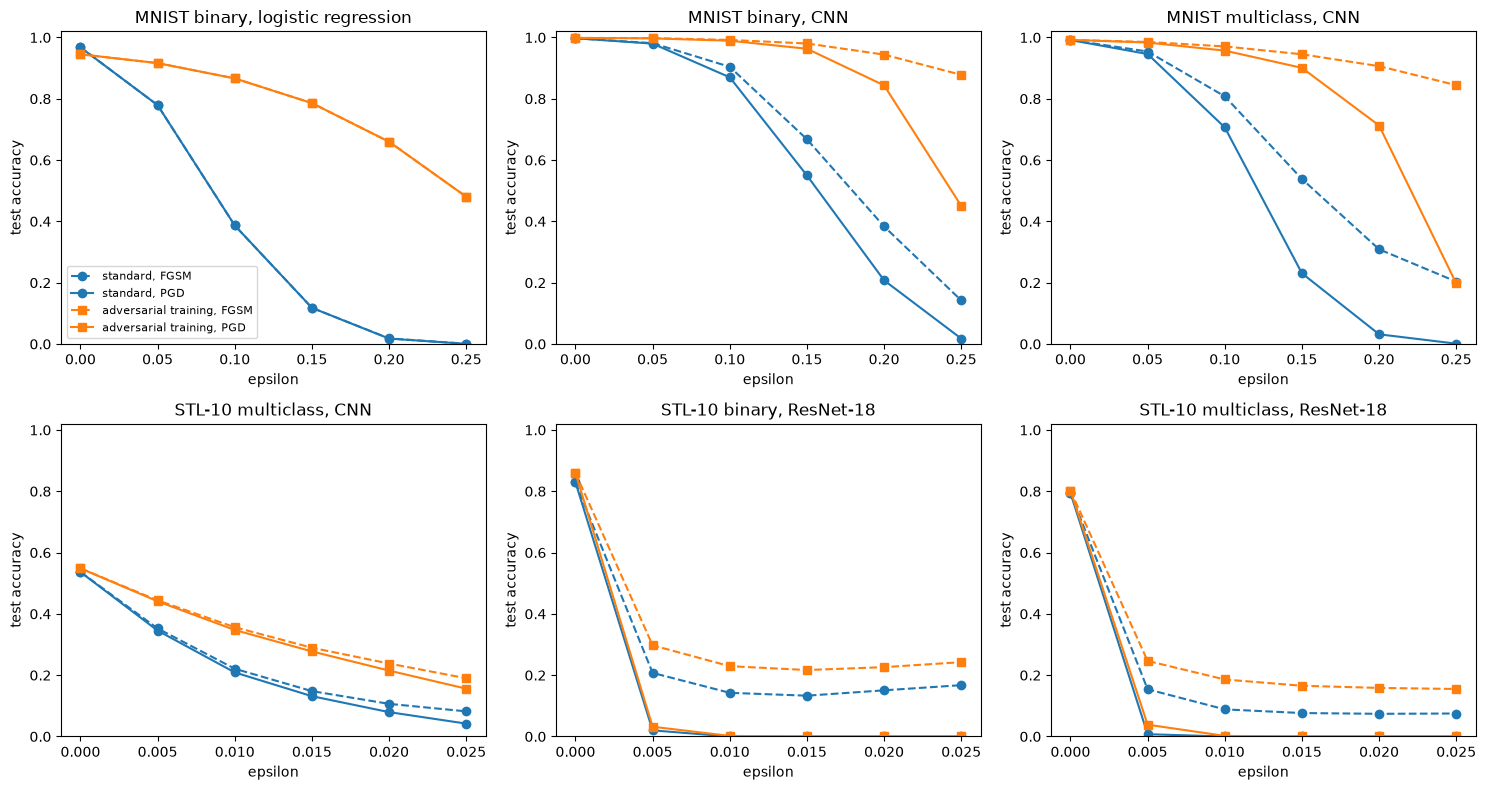

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

styles = {
    "standard, FGSM": dict(color="tab:blue", linestyle="--", marker="o"),
    "standard, PGD": dict(color="tab:blue", linestyle="-", marker="o"),
    "adversarial training, FGSM": dict(color="tab:orange", linestyle="--", marker="s"),
    "adversarial training, PGD": dict(color="tab:orange", linestyle="-", marker="s"),
}

for ax, (title, res) in zip(axes.flat, pgd_results.items()):
    for key, style in styles.items():
        ax.plot(res["epsilons"], res[key], label=key, **style)
    ax.set_title(title)
    ax.set_xlabel("epsilon")
    ax.set_ylabel("test accuracy")
    ax.set_ylim(0, 1.02)

axes.flat[0].legend(fontsize=8)
plt.tight_layout()

## Gap between FGSM and PGD

Accuracy under FGSM minus accuracy under PGD, at the largest epsilon. A large gap for the adversarially trained model means that it learned to resist FGSM specifically, not small perturbations in general.

In [6]:
for title, res in pgd_results.items():
    print(title)
    for model_name in ["standard", "adversarial training"]:
        gap = res[model_name + ", FGSM"][-1] - res[model_name + ", PGD"][-1]
        print("  ", model_name, ": FGSM", round(res[model_name + ", FGSM"][-1], 3),
              "| PGD", round(res[model_name + ", PGD"][-1], 3),
              "| gap", round(gap, 3))

MNIST binary, logistic regression
   standard : FGSM 0.001 | PGD 0.001 | gap 0.001
   adversarial training : FGSM 0.48 | PGD 0.48 | gap 0.0
MNIST binary, CNN
   standard : FGSM 0.142 | PGD 0.018 | gap 0.124
   adversarial training : FGSM 0.878 | PGD 0.451 | gap 0.427
MNIST multiclass, CNN
   standard : FGSM 0.203 | PGD 0.001 | gap 0.202
   adversarial training : FGSM 0.844 | PGD 0.198 | gap 0.647
STL-10 multiclass, CNN
   standard : FGSM 0.082 | PGD 0.042 | gap 0.04
   adversarial training : FGSM 0.19 | PGD 0.156 | gap 0.034
STL-10 binary, ResNet-18
   standard : FGSM 0.168 | PGD 0.0 | gap 0.168
   adversarial training : FGSM 0.242 | PGD 0.0 | gap 0.242
STL-10 multiclass, ResNet-18
   standard : FGSM 0.075 | PGD 0.0 | gap 0.075
   adversarial training : FGSM 0.155 | PGD 0.0 | gap 0.155


In [7]:
with open("pgd_results.json", "w") as f:
    json.dump(pgd_results, f, indent=2)

print("Saved pgd_results.json")

Saved pgd_results.json
